In [123]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [124]:
df = pd.read_csv('/content/lazada_data.csv')

In [125]:
df

,Name,Rating Score,Total Review,Seller Name,Location,Price (IDR)
0,Official Redmi A3 | Layar Muluz 90 Hz berukura...,4.936567,1072.0,Xiaomi,Kota Depok,1199000.0
1,Infinix Note 40 8/256GB - Up to 16GB Extended ...,4.938308,1702.0,Infinix,Kota Depok,2729000.0
2,Infinix Note 40 Pro 5G 8/256GB - Up to 16GB Ex...,4.931507,73.0,Infinix,Kota Depok,3579000.0
3,[PROMO] VIVO Y15S RAM 3GB / ROM 64GB - FULLSET...,5.000000,23.0,Mentari Cell,Kab. Madiun,999000.0
4,Samsung Galaxy A05 4/64 4/128,NaN,NaN,Ady Phone Store,Kab. Kebumen,1479000.0
...,...,...,...,...,...,...
3956,Samsung a12 Ram 6/128 mulus masih ori gransi r...,NaN,NaN,CANTIKA AMANAH CELULLER,Kab. Bogor,1725000.0
3957,SAMSUNG M10 2/16GB GARANSI RESMI SEIN ORIGINAL...,NaN,NaN,Honchi Celuller,Kota Tangerang,1575000.0
3958,Xiaomi redmi note 13 pro 5G 8/256 garansi resmi,NaN,NaN,Galeri-Hp 040595,Kota Jakarta Pusat,4398000.0
3959,samsung s21 ultra 256gb,NaN,NaN,Istoree,Kota Bandung,15650000.0


In [126]:
print(f'Baris : {df.shape[0]}')
print(f'Kolom : {df.shape[1]}')

Baris : 3961
Kolom : 6


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3961 entries, 0 to 3960
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Name          3961 non-null   object 
 1   Rating Score  1720 non-null   float64
 2   Total Review  1726 non-null   float64
 3   Seller Name   3961 non-null   object 
 4   Location      3961 non-null   object 
 5   Price (IDR)   3961 non-null   float64
dtypes: float64(3), object(3)
memory usage: 185.8+ KB


In [128]:
df.isna().sum()

,0
Name,0
Rating Score,2241
Total Review,2235
Seller Name,0
Location,0
Price (IDR),0


In [129]:
df.duplicated().sum()

np.int64(9)

Jadi **Rating Score dan Total Review memiliki missing value yang cukup besar**.

In [130]:
# cek data Rating_score,Total Review & Harga
print(f'Rating Score : {df["Rating Score"].notna()}')
print(f'Total Review : {df["Total Review"].notna()}')
print("Harga <= 0:",(df['Price (IDR)'] <= 0).sum())

Rating Score : 0        True
1        True
2        True
3        True
4       False
        ...  
3956    False
3957    False
3958    False
3959    False
3960    False
Name: Rating Score, Length: 3961, dtype: bool
Total Review : 0        True
1        True
2        True
3        True
4       False
        ...  
3956    False
3957    False
3958    False
3959    False
3960    False
Name: Total Review, Length: 3961, dtype: bool
Harga <= 0: 0


Hasilnya :
- Rating Score 1-5     = 0
- Total Review negatif = 0
- Harga < 0            = 0

**Berarti tidak ditemukan nilai yang tidak valid pada tiga variabel tersebut.**

In [131]:
df.drop_duplicates(inplace=True)

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df

,Name,Rating Score,Total Review,Seller Name,Location,Price (IDR)
0,Official Redmi A3 | Layar Muluz 90 Hz berukura...,4.936567,1072.0,Xiaomi,Kota Depok,1199000.0
1,Infinix Note 40 8/256GB - Up to 16GB Extended ...,4.938308,1702.0,Infinix,Kota Depok,2729000.0
2,Infinix Note 40 Pro 5G 8/256GB - Up to 16GB Ex...,4.931507,73.0,Infinix,Kota Depok,3579000.0
3,[PROMO] VIVO Y15S RAM 3GB / ROM 64GB - FULLSET...,5.000000,23.0,Mentari Cell,Kab. Madiun,999000.0
4,Samsung Galaxy A05 4/64 4/128,NaN,NaN,Ady Phone Store,Kab. Kebumen,1479000.0
...,...,...,...,...,...,...
3956,Samsung a12 Ram 6/128 mulus masih ori gransi r...,NaN,NaN,CANTIKA AMANAH CELULLER,Kab. Bogor,1725000.0
3957,SAMSUNG M10 2/16GB GARANSI RESMI SEIN ORIGINAL...,NaN,NaN,Honchi Celuller,Kota Tangerang,1575000.0
3958,Xiaomi redmi note 13 pro 5G 8/256 garansi resmi,NaN,NaN,Galeri-Hp 040595,Kota Jakarta Pusat,4398000.0
3959,samsung s21 ultra 256gb,NaN,NaN,Istoree,Kota Bandung,15650000.0


Setelah di Preprocessing : *3.961 → 3.952 data*

In [134]:
# EDA
df.describe()

,Rating Score,Total Review,Price (IDR)
count,1720.000000,1726.000000,3.952000e+03
mean,4.840749,131.239282,3.373935e+06
std,0.435869,550.874492,3.637555e+06
min,1.000000,0.000000,1.000000e+05
25%,4.869672,2.000000,1.450000e+06
50%,5.000000,9.000000,2.295000e+06
75%,5.000000,48.000000,3.899000e+06
max,5.000000,11409.000000,5.204700e+07


In [135]:
df['Price (IDR)'].describe().apply(lambda x: f'{x:.0f}')

,Price (IDR)
count,3952
mean,3373935
std,3637555
min,100000
25%,1450000
50%,2295000
75%,3899000
max,52047000


Hasil :
- Harga Minimum : **Rp.100.000**
- 25 % : **Rp1.450.000**
- Median : **Rp2.295.000**
- 75 % : **Rp3.899.000**
- Harga Maksimum : **Rp52.047.000**

Dari distribusi harga tersebut terdapat produk dengan harga jauh lebih tinggi

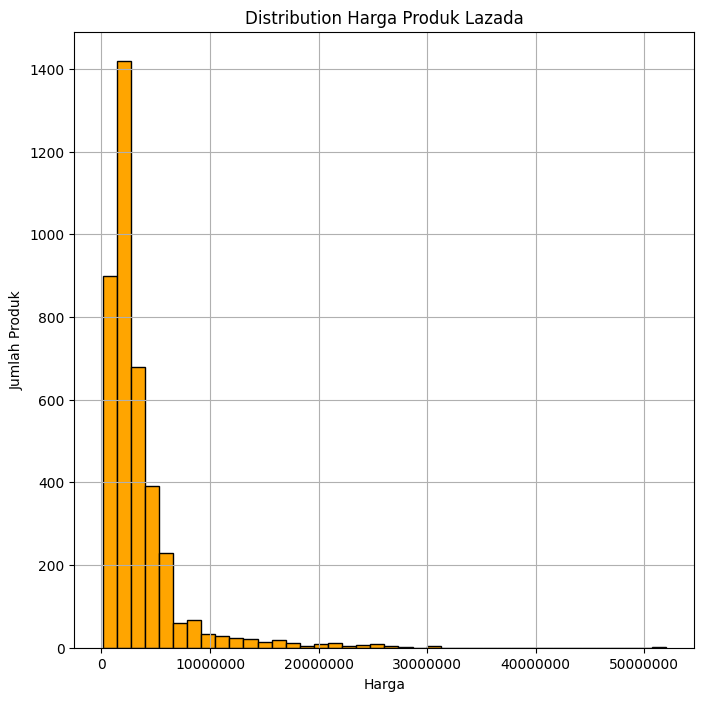

In [156]:
# Distribusi Harga
plt.figure(figsize=(8, 8))
plt.hist(df['Price (IDR)'], bins=40,color='orange',edgecolor='black')
plt.title('Distribution Harga Produk Lazada')
plt.xlabel('Harga')
plt.ylabel('Jumlah Produk')
plt.ticklabel_format(style='plain', axis='x')
plt.grid(True)
plt.show()

Sebagian besar produk berada pada rentang harga rendah hingga menengah

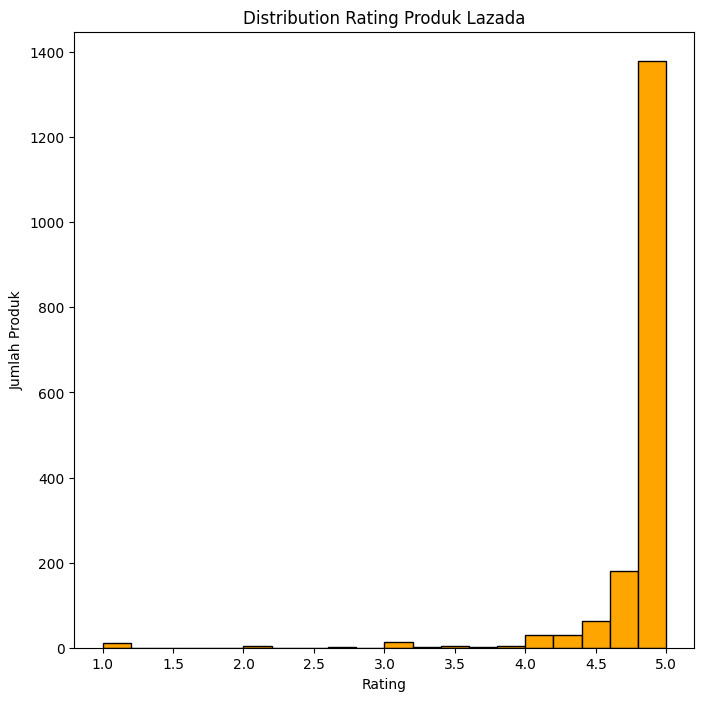

In [155]:
# Distribusi Rating
plt.figure(figsize=(8, 8))
plt.hist(df['Rating Score'],bins=20,color='orange',edgecolor='black')
plt.title('Distribution Rating Produk Lazada')
plt.xlabel('Rating')
plt.ylabel('Jumlah Produk')
plt.show()

**produk memiliki rating di atas 4,9**

Jadi rating produk di dataset Lazada ini secara umum sangat tinggi.

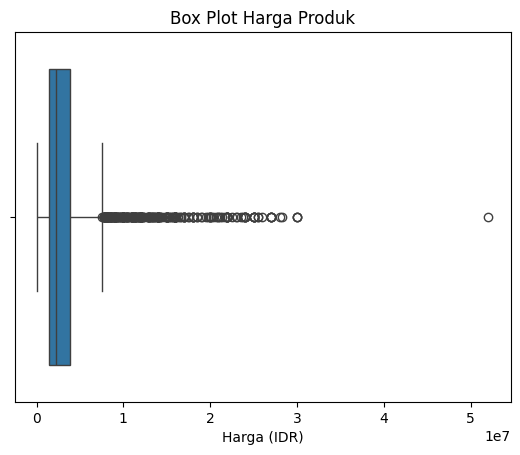

In [138]:
# boxplot pada harga
sns.boxplot(x=df['Price (IDR)'])
plt.title('Box Plot Harga Produk')
plt.xlabel('Harga (IDR)')
plt.show()

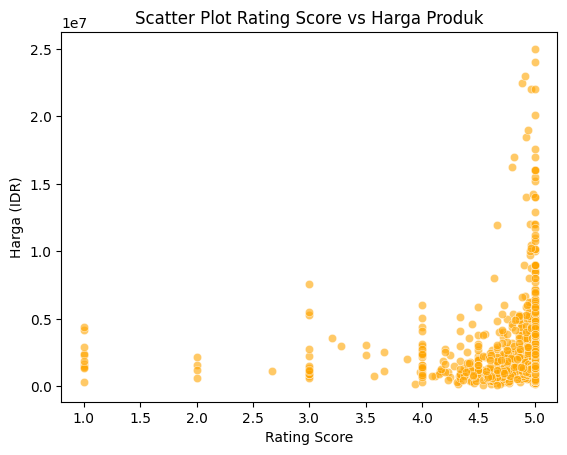

In [139]:
# scatter plot
sns.scatterplot(data=df,x='Rating Score',y='Price (IDR)',alpha=0.6,color='orange')
plt.title('Scatter Plot Rating Score vs Harga Produk')
plt.xlabel('Rating Score')
plt.ylabel('Harga (IDR)')
plt.show()

In [140]:
df[['Rating Score','Price (IDR)']].corr()

,Rating Score,Price (IDR)
Rating Score,1.000000,0.072081
Price (IDR),0.072081,1.000000


Korelasi yang di dapatkan sekitar = 0,072

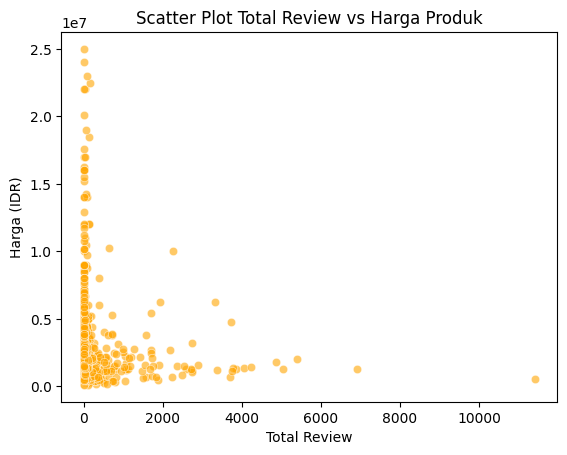

In [154]:
sns.scatterplot(data=df,x='Total Review',y='Price (IDR)',alpha=0.6,color='orange')
plt.title('Scatter Plot Total Review vs Harga Produk')
plt.xlabel('Total Review')
plt.ylabel('Harga (IDR)')
plt.show()

In [142]:
df[['Total Review','Price (IDR)']].corr()

,Total Review,Price (IDR)
Total Review,1.000000,-0.048106
Price (IDR),-0.048106,1.000000


Korelasi yang di dapatkan sekitar = -0,048

Dari Kolerasi kedua tersebut jumlah korelasi nya sangat lemah

In [143]:
bins = [0,500000,1000000,2000000,3000000,5000000,10000000,float('inf')]
labels = ['< Rp.500K','Rp.500k-1Jt','Rp.1Jt-2Jt','Rp.2Jt-3Jt','Rp.3Jt-5Jt','Rp.5Jt-10Jt','> Rp.10Jt']
df['Harga Range'] = pd.cut(df['Price (IDR)'],bins=bins,labels=labels,right=False)

In [144]:
harga_count = df['Harga Range'].value_counts().sort_index()

In [145]:
harga_count

,count
Harga Range,
< Rp.500K,83
Rp.500k-1Jt,267
Rp.1Jt-2Jt,1404
Rp.2Jt-3Jt,792
Rp.3Jt-5Jt,788
Rp.5Jt-10Jt,432
> Rp.10Jt,186


Rentang Rp1–2 juta merupakan kategori harga yang paling dominan, dengan 1.404 produk.`

In [146]:
# Lokasi
df['Location'].value_counts()

,count
Location,
Kota Jakarta Barat,477
Kota Surabaya,394
Kota Jakarta Pusat,392
Kota Jakarta Utara,307
Kab. Bogor,241
...,...
Kab. Bondowoso,1
Kab. Banyuwangi,1
Kab. Boyolali,1


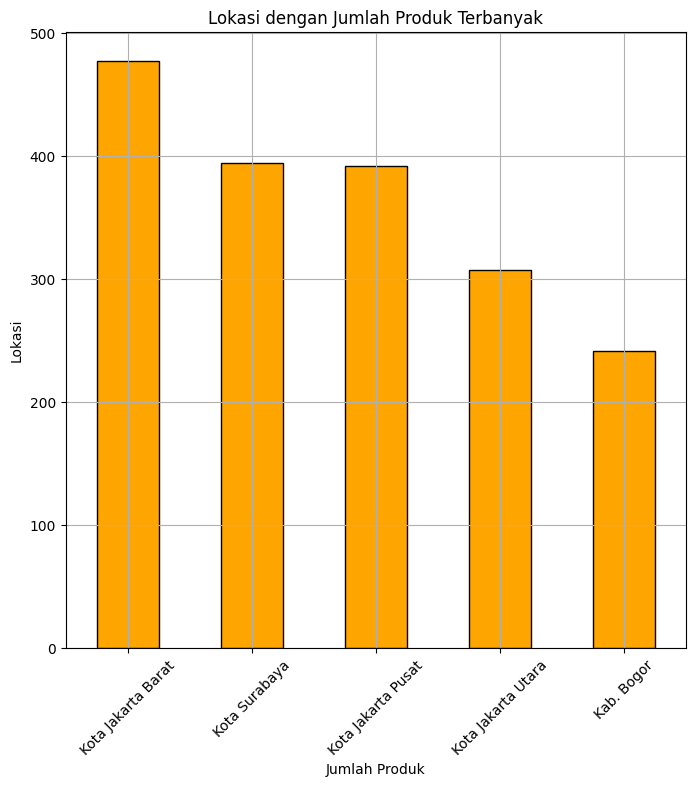

In [152]:
plt.figure(figsize=(8, 8))
df['Location'].value_counts().head(5).plot(kind='bar',color='orange',edgecolor='black')
plt.title('Lokasi dengan Jumlah Produk Terbanyak')
plt.xlabel('Jumlah Produk')
plt.ylabel('Lokasi')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Dari data Lokasi :
- Kota Jakarta Barat : **482 Produk**
- Kota Surabaya : **394 Produk**
- Kota Jakarta Pusat : **392 Produk**
- Kota Jakarta Utara : **307 Produk**
- Kab. Bogor : **241 Produk**

**Jakarta Barat menjadi lokasi dengan jumlah listing produk terbanyak**

In [148]:
df['Seller Name'].value_counts()

,count
Seller Name,
HP SECOND JOSS,114
wwponsel_hangtuah,98
Apollo Gadget Store,96
Mentari Cell,89
EVOGAD,76
...,...
velvet cellular,1
Makassar Accesoris,1
HOKI_999,1


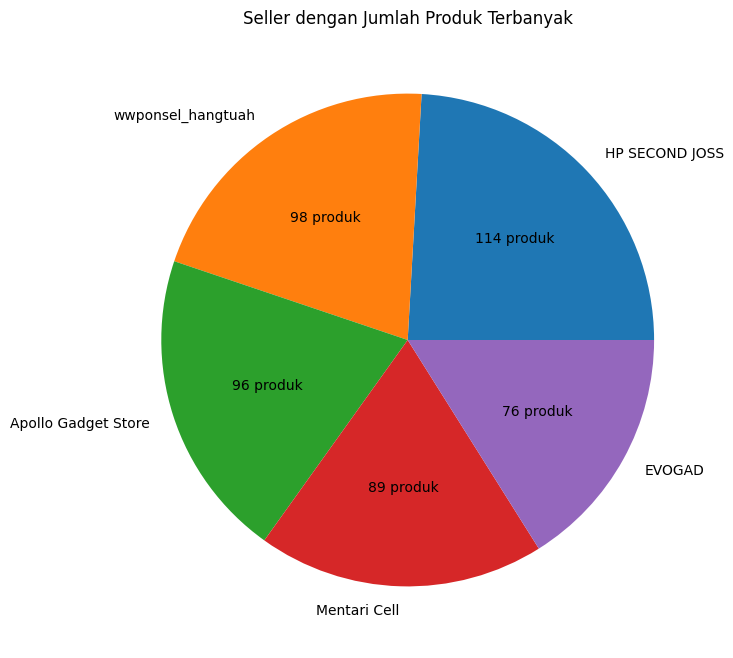

In [151]:
data = df['Seller Name'].value_counts().head(5)
plt.figure(figsize=(8, 8))
plt.pie(data,labels=data.index,autopct=lambda p: f'{p * data.sum() / 100:.0f} produk')
plt.title('Seller dengan Jumlah Produk Terbanyak')
plt.show()

Dari data Nama Seller :
- HP SECOND JOSS : **114 Produk**
- wwponsel_hangtuah : **99 Produk**
- Apollo Gadget Store : **96 Produk**
- Mentari Cell : **89 Produk**
- EVOGAD : **76 Produk**

**HP SECOND JOSS menjadi Seller dengan jumlah listing produk terbanyak**